# Assignment 2: Convolutional Neural Networks and Image Classification

Name: He Xiao  
UNI: hx2425  
GitHub repository: [HotcatX/API-test](https://github.com/HotcatX/API-test)

This submission implements the required PyTorch CNN, trains it on CIFAR-10,
adds an image classification endpoint to the existing FastAPI application,
and answers the six CNN arithmetic questions.

The notebook uses the saved model and recorded training results. Running its
cells performs small verification and inference checks; it does not retrain
the model or download the full dataset.

## Part I. Practice: CNN Architecture

The required input is a 64 × 64 RGB image. PyTorch represents a batch as
`(N, 3, 64, 64)`, where `N` is the batch size. The final layer produces ten
logits, one for each CIFAR-10 class. During training, these logits are passed
directly to `CrossEntropyLoss`. Softmax is applied only when reporting
prediction scores.

Run the notebook with the project's `.venv` Python kernel. From the repository
root, the environment can be prepared with:

```bash
uv sync --locked --group dev --group notebook
uv run --group notebook python -m ipykernel install --sys-prefix \
  --name api-test --display-name "API-test (.venv)"
```

In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import math
import os
import sys

import torch
from torch import nn
from IPython.display import Markdown, display
from PIL import Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates
            if (path / "app/cnn_model.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from app.cnn_model import (
    ARCHITECTURE, CLASSES, PREPROCESSING, AssignmentCNN, preprocess,
)

torch.set_num_threads(min(2, torch.get_num_threads()))
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Using project .venv:", Path(sys.prefix).resolve() == (ROOT / ".venv").resolve())
print("Classes:", ", ".join(CLASSES))

Python: 3.12.14
PyTorch: 2.8.0
Using project .venv: True
Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


### Model implementation

The following cell displays the actual class imported by the training script
and API. This keeps the submitted implementation and deployed model consistent.

In [2]:
print(inspect.getsource(AssignmentCNN))

class AssignmentCNN(nn.Module):
    """Accept N x 3 x 64 x 64 tensors and return N x 10 unnormalized logits."""

    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 100),
            nn.ReLU(),
            nn.Linear(100, len(CLASSES)),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))



### Output shapes and parameters

Both convolutions use kernel size 3, stride 1, and padding 1, preserving
height and width. Each 2 × 2 max-pooling layer halves them. After two pooling
layers, the feature tensor is $(N,32,16,16)$, so the flattened size is

$$32\times16\times16=8192.$$

| Layer | Output shape | Trainable parameters |
| --- | --- | ---: |
| Input | $(N,3,64,64)$ | 0 |
| Conv2d, 3 → 16, 3 × 3 | $(N,16,64,64)$ | 448 |
| ReLU | $(N,16,64,64)$ | 0 |
| MaxPool2d, 2 × 2 | $(N,16,32,32)$ | 0 |
| Conv2d, 16 → 32, 3 × 3 | $(N,32,32,32)$ | 4,640 |
| ReLU | $(N,32,32,32)$ | 0 |
| MaxPool2d, 2 × 2 | $(N,32,16,16)$ | 0 |
| Flatten | $(N,8192)$ | 0 |
| Linear, 8192 → 100 | $(N,100)$ | 819,300 |
| ReLU | $(N,100)$ | 0 |
| Linear, 100 → 10 | $(N,10)$ | 1,010 |
| Total | $(N,10)$ | 825,398 |

Including one bias per output channel or unit,

$$
\begin{aligned}
P_{\mathrm{conv1}} &=16(3\times3\times3+1)=448,\\
P_{\mathrm{conv2}} &=32(16\times3\times3+1)=4{,}640,\\
P_{\mathrm{fc1}} &=8192\times100+100=819{,}300,\\
P_{\mathrm{fc2}} &=100\times10+10=1{,}010,\\
P_{\mathrm{total}} &=448+4{,}640+819{,}300+1{,}010\\
&=825{,}398.
\end{aligned}
$$

In [3]:
# This untrained instance is used only to verify the architecture.
model = AssignmentCNN()
traces = []

def record_shape(name):
    def hook(module, inputs, output):
        traces.append((name, type(module).__name__, tuple(output.shape)))
    return hook

handles = [
    module.register_forward_hook(record_shape(name))
    for name, module in model.named_modules()
    if name and not list(module.children())
]
with torch.inference_mode():
    logits = model(torch.zeros(1, 3, 64, 64))
for handle in handles:
    handle.remove()

expected = [
    (1, 16, 64, 64), (1, 16, 64, 64), (1, 16, 32, 32),
    (1, 32, 32, 32), (1, 32, 32, 32), (1, 32, 16, 16),
    (1, 8192), (1, 100), (1, 100), (1, 10),
]
assert [shape for _, _, shape in traces] == expected
for name, kind, shape in traces:
    print(f"{name:15} {kind:12} {shape}")

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert parameter_count == 825_398
print(f"Trainable parameters: {parameter_count:,}")

features.0      Conv2d       (1, 16, 64, 64)
features.1      ReLU         (1, 16, 64, 64)
features.2      MaxPool2d    (1, 16, 32, 32)
features.3      Conv2d       (1, 32, 32, 32)
features.4      ReLU         (1, 32, 32, 32)
features.5      MaxPool2d    (1, 32, 16, 16)
classifier.0    Flatten      (1, 8192)
classifier.1    Linear       (1, 100)
classifier.2    ReLU         (1, 100)
classifier.3    Linear       (1, 10)
Trainable parameters: 825,398


## Part II. Practice: Training and API Deployment

### Data and preprocessing

CIFAR-10 contains 60,000 RGB images of size 32 × 32 in ten classes: 50,000
official training images and 10,000 official test images. The official
training set is split into 45,000 training and 5,000 validation examples.
The checkpoint with the highest validation accuracy is selected, then
evaluated once on the held-out test set.

All images are converted to RGB and resized to 64 × 64 using bilinear
interpolation to match the required architecture. Pixel values are scaled
to [0, 1] and normalized with channel-wise mean and standard deviation of
0.5, giving values in approximately [-1, 1]. Training additionally uses
random cropping and horizontal flipping. Validation, testing, and API
inference use the same deterministic preprocessing function.

[CIFAR-10 dataset source](https://www.cs.toronto.edu/~kriz/cifar.html)

In [4]:
metrics = json.loads((ROOT / "assignment2/training_metrics.json").read_text())
history = json.loads((ROOT / "assignment2/training_history.json").read_text())
sample_metadata = json.loads((ROOT / "assignment2/sample_metadata.json").read_text())

assert metrics["classes"] == list(CLASSES)
assert metrics["architecture"] == ARCHITECTURE
assert metrics["preprocessing"] == PREPROCESSING
assert metrics["parameter_count"] == parameter_count
assert len(history) == metrics["epochs"]
assert metrics["train_count"] + metrics["validation_count"] == 50_000
assert metrics["test"]["count"] == metrics["test_count"] == 10_000
assert metrics["test_evaluations"] == 1

config_keys = [
    "dataset", "train_count", "validation_count", "test_count", "seed",
    "epochs", "batch_size", "optimizer", "initial_learning_rate",
    "weight_decay", "scheduler", "minimum_learning_rate", "loss",
    "device", "pytorch_version", "training_augmentation",
]
table = ["| Setting | Recorded value |", "| --- | --- |"]
table.extend(f"| {key} | {metrics[key]} |" for key in config_keys)
display(Markdown("\n".join(table)))

| Setting | Recorded value |
| --- | --- |
| dataset | CIFAR-10 |
| train_count | 45000 |
| validation_count | 5000 |
| test_count | 10000 |
| seed | 42 |
| epochs | 15 |
| batch_size | 128 |
| optimizer | Adam |
| initial_learning_rate | 0.001 |
| weight_decay | 0.0001 |
| scheduler | CosineAnnealingLR |
| minimum_learning_rate | 1e-05 |
| loss | CrossEntropyLoss on logits |
| device | mps |
| pytorch_version | 2.8.0 |
| training_augmentation | Resize 64x64 bilinear; random crop 64x64 with reflect padding 8; random horizontal flip |

### Recorded training results

The results below are read from the training artifacts produced by
`scripts/train_cifar10.py`. Training accuracy uses augmented inputs, while
validation accuracy uses deterministic preprocessing. Seeds are fixed, but
hardware, backend, and library differences can still affect floating-point
results. The test set is not used to select the epoch.

In [5]:
table = [
    "| Epoch | Learning rate | Train loss | Train accuracy | Val. loss | Val. accuracy |",
    "| ---: | ---: | ---: | ---: | ---: | ---: |",
]
for record in history:
    table.append(
        f"| {record['epoch']} | {record['learning_rate']:.6f} | "
        f"{record['train_loss']:.4f} | {record['train_accuracy']:.2%} | "
        f"{record['validation_loss']:.4f} | {record['validation_accuracy']:.2%} |"
    )
display(Markdown("\n".join(table)))

selected = next(record for record in history
                if record["epoch"] == metrics["best_epoch"])
assert math.isclose(selected["validation_accuracy"],
                    metrics["best_validation_accuracy"], abs_tol=1e-12)
assert math.isclose(metrics["best_validation_accuracy"],
                    max(row["validation_accuracy"] for row in history), abs_tol=1e-12)
print("Selected checkpoint epoch:", metrics["best_epoch"])
print(f"Best validation accuracy: {metrics['best_validation_accuracy']:.2%}")
print(f"Held-out test accuracy: {metrics['test']['accuracy']:.2%}")
print(f"Held-out test loss: {metrics['test']['loss']:.4f}")
print(f"Recorded elapsed time: {metrics['elapsed_seconds'] / 60:.2f} minutes")

| Epoch | Learning rate | Train loss | Train accuracy | Val. loss | Val. accuracy |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 1 | 0.001000 | 1.5895 | 42.64% | 1.3212 | 53.52% |
| 2 | 0.000989 | 1.3520 | 51.21% | 1.2052 | 56.96% |
| 3 | 0.000957 | 1.2687 | 54.65% | 1.1393 | 59.48% |
| 4 | 0.000905 | 1.2032 | 56.87% | 1.1056 | 60.54% |
| 5 | 0.000836 | 1.1497 | 59.06% | 1.0349 | 62.90% |
| 6 | 0.000752 | 1.1015 | 60.93% | 1.0057 | 64.12% |
| 7 | 0.000658 | 1.0561 | 62.54% | 0.9647 | 65.52% |
| 8 | 0.000557 | 1.0239 | 63.58% | 0.9292 | 67.10% |
| 9 | 0.000453 | 0.9966 | 64.53% | 0.9112 | 67.96% |
| 10 | 0.000352 | 0.9646 | 66.01% | 0.8945 | 68.64% |
| 11 | 0.000258 | 0.9426 | 66.57% | 0.8711 | 69.64% |
| 12 | 0.000174 | 0.9286 | 66.98% | 0.8677 | 69.70% |
| 13 | 0.000105 | 0.9146 | 67.62% | 0.8628 | 69.92% |
| 14 | 0.000053 | 0.9020 | 68.09% | 0.8573 | 70.08% |
| 15 | 0.000021 | 0.9005 | 68.10% | 0.8536 | 70.12% |

Selected checkpoint epoch: 15
Best validation accuracy: 70.12%
Held-out test accuracy: 70.42%
Held-out test loss: 0.8505
Recorded elapsed time: 1.32 minutes


In [6]:
test = metrics["test"]
confusion = test["confusion_matrix_rows_true_columns_predicted"]
correct = sum(confusion[i][i] for i in range(len(CLASSES)))
count = sum(sum(row) for row in confusion)
assert count == 10_000
assert math.isclose(correct / count, test["accuracy"], abs_tol=1e-12)

table = ["| Class | Test accuracy |", "| --- | ---: |"]
for name in CLASSES:
    table.append(f"| {name} | {test['per_class_accuracy'][name]:.2%} |")
display(Markdown("\n".join(table)))
print(f"Correct test predictions: {correct:,} / {count:,}")

| Class | Test accuracy |
| --- | ---: |
| airplane | 74.80% |
| automobile | 83.70% |
| bird | 56.50% |
| cat | 50.10% |
| deer | 61.20% |
| dog | 61.70% |
| frog | 82.60% |
| horse | 75.90% |
| ship | 82.40% |
| truck | 75.30% |

Correct test predictions: 7,042 / 10,000


### Loading the saved checkpoint

The repository includes the trained checkpoint at `models/cifar10_cnn.pt`.
Its state dictionary is loaded on the CPU for portable inference. The
following cell verifies its SHA-256 hash against the training record and
checks that its classes and preprocessing match the implementation.

In [7]:
checkpoint_path = ROOT / metrics["checkpoint"]
actual_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
assert actual_sha256 == metrics["checkpoint_sha256"]
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["classes"] == list(CLASSES)
assert checkpoint["preprocessing"] == PREPROCESSING
assert checkpoint["architecture"] == ARCHITECTURE
assert checkpoint["epoch"] == metrics["best_epoch"]
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()
print("Loaded:", metrics["checkpoint"])
print("SHA-256:", actual_sha256)
print("Selected epoch:", checkpoint["epoch"])

Loaded: models/cifar10_cnn.pt
SHA-256: 60b6a211c0ae0f11ec516c5fe7a86b245c5e2ca96b09cf45a211df84705b7030
Selected epoch: 15


### Example image and direct inference

The example is the original image at index 0 of the official CIFAR-10 test
split, whose label is `cat`. The index was fixed independently of the model's
prediction. The single example illustrates the interface; aggregate test
accuracy is reported above.

Original image dimensions: (32, 32)


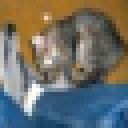

True class: cat
Predicted class: cat
Softmax score: 0.6336


In [8]:
sample_path = ROOT / sample_metadata["image"]
assert sample_metadata["split"] == "test"
assert sample_metadata["index"] == 0
assert sample_metadata["true_class"] == "cat"
with Image.open(sample_path) as image:
    example = image.convert("RGB")
print("Original image dimensions:", example.size)
display(example.resize((128, 128), Image.Resampling.NEAREST))
image_tensor = preprocess(example).unsqueeze(0)
assert tuple(image_tensor.shape) == (1, 3, 64, 64)
with torch.inference_mode():
    direct_scores = model(image_tensor).softmax(dim=1)[0]
direct_id = int(direct_scores.argmax())
print("True class:", sample_metadata["true_class"])
print("Predicted class:", CLASSES[direct_id])
print(f"Softmax score: {float(direct_scores[direct_id]):.4f}")

### FastAPI interface

`POST /classify` accepts an image as a multipart upload with the field name
`file`. It returns `predicted_class`, `class_id`, `confidence`, probabilities
for all ten classes, the model name, and the preprocessed tensor shape.
`confidence` is the largest softmax score; it is not a guarantee of correctness
or a calibrated probability.

The existing `/`, `/generate`, and `/embedding` routes remain available.
Interactive endpoint documentation is at `http://localhost:8000/docs`.

Supported uploads are PNG, JPEG, and WEBP. Invalid images return an error
instead of a prediction. The endpoint uses the saved trained weights and
the same preprocessing as validation and testing.

In [9]:
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message="Using `httpx` with `starlette.testclient` is deprecated.*"
    )
    from fastapi.testclient import TestClient
from app.main import app

with TestClient(app) as client:
    with sample_path.open("rb") as image_file:
        response = client.post(
            "/classify",
            files={"file": (sample_path.name, image_file, "image/png")},
        )
assert response.status_code == 200, response.text
result = response.json()
assert result["predicted_class"] == CLASSES[direct_id]
assert result["class_id"] == direct_id
assert result["input_shape"] == [1, 3, 64, 64]
assert set(result["probabilities"]) == set(CLASSES)
assert math.isclose(sum(result["probabilities"].values()), 1.0, abs_tol=1e-6)
assert math.isclose(result["confidence"],
                    float(direct_scores[direct_id]), abs_tol=1e-6)
print("HTTP status:", response.status_code)
print(json.dumps(result, indent=2))

HTTP status: 200
{
  "predicted_class": "cat",
  "class_id": 3,
  "confidence": 0.6336061954498291,
  "probabilities": {
    "airplane": 0.04967287555336952,
    "automobile": 0.0007287085754796863,
    "bird": 0.06305578351020813,
    "cat": 0.6336061954498291,
    "deer": 0.0013369936496019363,
    "dog": 0.21060605347156525,
    "frog": 0.010417453944683075,
    "horse": 0.0012900029541924596,
    "ship": 0.027932235971093178,
    "truck": 0.0013537176419049501
  },
  "model": "assignment2-cifar10-cnn",
  "input_shape": [
    1,
    3,
    64,
    64
  ]
}


### Running and reproducing the project

Run the API locally from the repository root using the project environment:

```bash
uv sync --locked --group dev --group notebook
uv run uvicorn app.main:app --host 0.0.0.0 --port 8000
```

In another terminal, upload the included image:

```bash
curl -X POST http://localhost:8000/classify \
  -F "file=@assignment2/sample_cat.png"
```

Alternatively, build and start the Docker deployment:

```bash
docker build -t api-test:assignment2 .
docker run --rm -p 8000:80 api-test:assignment2
```

The same curl request works against the container. The trained checkpoint
is included in the image, so serving predictions does not require training
or a CIFAR-10 download.

Training is an explicit, separate operation. The command below recreates
the recorded configuration and downloads CIFAR-10 into `data/` when needed:

```bash
uv run python scripts/train_cifar10.py --epochs 15 --batch-size 128 --learning-rate 0.001 --seed 42
```

This overwrites the saved checkpoint and result artifacts with the new run.
To run the automated checks without retraining:

```bash
uv run --group dev pytest -q
```

## Part III. Theory: Arithmetic of CNNs

For these calculations, let $n$ be the input height or width, $k$ the kernel size, $s$ the stride, and $p$ the padding on each side. With dilation $1$, the output size along one spatial dimension is

$$
n_{\mathrm{out}}=\left\lfloor\frac{n+2p-k}{s}\right\rfloor+1.
$$

The same calculation applies independently to height and width. A convolution's number of output channels equals its number of filters. Shapes in the answers use height-width-channels notation; PyTorch tensors use batch-channels-height-width notation. [PyTorch Conv2d documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)

### Question 1

Given a $32\times32\times3$ input, eight $5\times5$ filters, stride $1$, and no padding, what is the output size?

Substitute $n=32$, $k=5$, $s=1$, and $p=0$:

$$
H_{\mathrm{out}}=W_{\mathrm{out}}
=\left\lfloor\frac{32+2(0)-5}{1}\right\rfloor+1
=27+1=28.
$$

Each filter combines information from all three input channels and produces one feature map. Eight filters produce eight output channels, so the output shape is

$$
\boxed{28\times28\times8}.
$$

For a batch of $N$ images, the PyTorch output shape is $(N,8,28,28)$.

### Question 2

How does the output size in Question 1 change if padding is changed to “same”?

With “same” padding and stride $1$, the output keeps the input's spatial dimensions. A $5\times5$ kernel requires padding of

$$
p=\frac{k-1}{2}=\frac{5-1}{2}=2
$$

on each side. Therefore,

$$
H_{\mathrm{out}}=W_{\mathrm{out}}
=\left\lfloor\frac{32+2(2)-5}{1}\right\rfloor+1
=31+1=32.
$$

There are still eight filters, so the output shape is

$$
\boxed{32\times32\times8}.
$$

### Question 3

What is the output spatial size for a $64\times64$ input, a $3\times3$ filter, stride $2$, and no padding?

Substitute $n=64$, $k=3$, $s=2$, and $p=0$:

$$
\begin{aligned}
H_{\mathrm{out}}=W_{\mathrm{out}}
&=\left\lfloor\frac{64+2(0)-3}{2}\right\rfloor+1\\
&=\left\lfloor30.5\right\rfloor+1\\
&=30+1=31.
\end{aligned}
$$

The fractional value is rounded down because only positions where the entire kernel fits inside the input are valid. The output spatial size is

$$
\boxed{31\times31}.
$$

The number of output channels would depend on the number of filters, which is not specified.

### Question 4

What is the output size after $2\times2$ max pooling with stride $2$ on a $16\times16$ feature map?

Using $n=16$, $k=2$, $s=2$, and the default of no padding,

$$
H_{\mathrm{out}}=W_{\mathrm{out}}
=\left\lfloor\frac{16-2}{2}\right\rfloor+1
=7+1=8.
$$

Each non-overlapping $2\times2$ region is replaced by its maximum. Both spatial dimensions are halved, giving

$$
\boxed{8\times8}.
$$

Pooling preserves the number of channels. If there are $C$ input channels, the complete output shape is $8\times8\times C$.

### Question 5

What is the output shape after two successive convolutions on a $128\times128$ image, each using a $3\times3$ kernel, stride $1$, and “same” padding?

Each convolution uses padding

$$
p=\frac{3-1}{2}=1.
$$

After the first convolution,

$$
H_1=W_1
=\left\lfloor\frac{128+2(1)-3}{1}\right\rfloor+1
=127+1=128.
$$

After the second convolution,

$$
H_2=W_2
=\left\lfloor\frac{128+2(1)-3}{1}\right\rfloor+1
=127+1=128.
$$

Therefore, the final spatial shape is

$$
\boxed{128\times128}.
$$

The number of filters is not provided, so the complete output shape cannot be determined numerically. If the second convolution has $C_2$ filters, the complete shape is $128\times128\times C_2$.

### Question 6

What happens if `model.train()` is removed before the training loop?

Calling `model.train()` puts the model and its submodules into training mode. Removing it does not necessarily prevent training.

A newly created PyTorch model starts in training mode by default. If it has never been switched to evaluation mode, removing `model.train()` leaves it in training mode and does not change its behavior. [PyTorch modules documentation](https://docs.pytorch.org/docs/stable/notes/modules.html)

If `model.eval()` was called earlier, the model remains in evaluation mode unless training mode is restored. This matters for layers such as Dropout and BatchNorm: Dropout remains inactive, and BatchNorm uses its stored running statistics instead of its training behavior. [PyTorch Module documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html)

The CNN in this assignment contains only convolution, ReLU, max-pooling, flattening, and linear layers. These layers have the same forward behavior in both modes, so removing `model.train()` does not change this particular network's forward computation.

Training mode is separate from gradient tracking. `model.eval()` does not disable gradients, and `model.train()` does not override `torch.no_grad()` or `torch.inference_mode()`. Parameter updates still require gradient computation, `loss.backward()`, and an optimizer step. Explicitly calling `model.train()` before training remains good practice. [PyTorch autograd documentation](https://docs.pytorch.org/docs/stable/notes/autograd.html)

### Numerical checks for Questions 1-5

These calculations independently verify the spatial-size arithmetic.

In [10]:
def spatial_size(n, kernel, stride=1, padding=0):
    return (n + 2 * padding - kernel) // stride + 1

q1 = spatial_size(32, 5)
q2 = spatial_size(32, 5, padding=2)
q3 = spatial_size(64, 3, stride=2)
q4 = spatial_size(16, 2, stride=2)
q5_first = spatial_size(128, 3, padding=1)
q5_second = spatial_size(q5_first, 3, padding=1)
assert (q1, q2, q3, q4, q5_first, q5_second) == (28, 32, 31, 8, 128, 128)
print("Q1:", (q1, q1, 8))
print("Q2:", (q2, q2, 8))
print("Q3 spatial size:", (q3, q3))
print("Q4 spatial size:", (q4, q4))
print("Q5 spatial size:", (q5_second, q5_second))

Q1: (28, 28, 8)
Q2: (32, 32, 8)
Q3 spatial size: (31, 31)
Q4 spatial size: (8, 8)
Q5 spatial size: (128, 128)


### Training-mode check for Question 6

This check uses the current network to verify that switching between
training and evaluation modes does not change its forward output. It also
checks separately that evaluation mode leaves automatic differentiation
enabled when gradient tracking is otherwise active.

In [11]:
assert AssignmentCNN().training is True
model.train()
with torch.inference_mode():
    training_output = model(image_tensor)
model.eval()
with torch.inference_mode():
    evaluation_output = model(image_tensor)
assert torch.equal(training_output, evaluation_output)
print("Same forward output in both modes:",
      torch.equal(training_output, evaluation_output))

with torch.enable_grad():
    evaluation_with_grad = model(image_tensor)
assert evaluation_with_grad.requires_grad
print("Evaluation mode still allows gradients:",
      evaluation_with_grad.requires_grad)
with torch.no_grad():
    without_grad = model(image_tensor)
assert not without_grad.requires_grad
print("no_grad disables gradient tracking:", not without_grad.requires_grad)

Same forward output in both modes: True
Evaluation mode still allows gradients: True
no_grad disables gradient tracking: True


## References

- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html):
  convolution arguments and output-shape formula.
- [PyTorch MaxPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html):
  max-pooling behavior and output dimensions.
- [PyTorch modules](https://docs.pytorch.org/docs/stable/notes/modules.html):
  module construction and the default training mode.
- [PyTorch Module](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html):
  `train()` and `eval()`.
- [PyTorch autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html):
  the distinction between evaluation mode and gradient tracking.
- [PyTorch CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html):
  classification loss applied to unnormalized logits.
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html):
  image dimensions, classes, and official train/test split.
- Alex Krizhevsky (2009), [Learning Multiple Layers of Features from Tiny Images](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf).